![Banner](../../../../Images/Banner/07_remote_sensing/09_02_banner_rs_optical.png)


# Sentinel-5P and Sentinel-5: Mapping Air Pollution from Orbit

Sentinel-5P (Copernicus, ESA) carries TROPOMI, a spectrometer that retrieves trace gas columns such as NO2, SO2, CO, CH4 and HCHO, plus aerosol and cloud information, from daily global coverage.


## Overview

Its successor, Sentinel-5, began flying in 2025 on EUMETSAT's MetOp-SG A satellites. This module works with real Sentinel-5P data over two whole AOIs: Bangladesh on an ordinary dry season day, and New York State during a Canadian wildfire smoke event. Products are read, masked and gridded with `geolattice.rsense.atmosphere.sentinel_5p`, clipped to the administrative boundary, and resampled to a 1 km grid with a thin plate spline.


## Core concepts

### Learning objectives

1. Know the Sentinel-5P product family and the `qa_value` quality convention.
2. Read a real TROPOMI Level 2 product from its nested `PRODUCT` group.
3. Select the regional segment(s) that cover an entire country or state from a Planetary
   Computer STAC search, including the case where two adjacent segments are both needed.
4. Clip quality-filtered swath points to an exact administrative boundary polygon.
5. Resample irregular swath points onto a regular 1 km grid with a thin plate spline, in a
   projected (metres) coordinate system, and understand why that differs from simple binning.
6. Build a real six-pollutant picture of a whole country (Bangladesh, dry season) and of a
   single transient smoke event over a US state (Canadian wildfire smoke over New York).
7. Recognize a genuine data availability limit (methane under heavy smoke) rather than mistake
   it for a bug.
8. Check processing consistency across the files a single download actually needs to combine.

### Contents

1. The two missions
2. Platforms
3. Sensors
4. Spectral bands
5. Data products
6. Applications
7. Where to get the data
8. Data
9. Setup
10. The Sentinel-5P product family and qa_value quality filtering
11. Boundaries, regional segments and the clip-then-resample workflow
12. Case study A: Bangladesh, dry season, 15 January 2025
13. Case study B: New York State under Canadian wildfire smoke, 15 July 2026
14. Checking processing consistency across combined downloads
15. Summary, exercises and references


## The two missions

"Sentinel-5" covers two related missions for monitoring atmospheric composition.

- **Sentinel-5 Precursor (Sentinel-5P)**: a dedicated satellite carrying the TROPOMI
  instrument, in orbit since 2017.
- **Sentinel-5**: a spectrometer carried on EUMETSAT's MetOp Second Generation (MetOp-SG)
  A-type weather satellites. The first unit, Sentinel-5A, launched in August 2025.

**Heritage.** These missions build on earlier European and Dutch atmospheric spectrometers:
GOME on ERS-2 (1995), SCIAMACHY on Envisat (2002 to 2012), OMI on NASA's Aura satellite (2004,
a Dutch-Finnish instrument), and GOME-2 on the first-generation MetOp satellites.

**Why a precursor?** Sentinel-5P was designed to close the data gap between the loss of
Envisat and the dedicated Copernicus atmospheric missions, Sentinel-4 and Sentinel-5.

**Sentinel-5P**
- Launched on 13 October 2017 from the Plesetsk Cosmodrome in Russia on a Rockot.
- TROPOMI was co-funded by the Netherlands and ESA. KNMI handles mission planning for the
  instrument, and ESOC handles mission control.
- Design life was about 7 years. Operations are secured until the end of 2027.
- Its loose formation with Suomi-NPP ends by Q4 2026. Suomi-NPP data delivery itself stops on
  1 November 2026, so the cloud products that rely on VIIRS will be affected.

**Sentinel-5 (on MetOp-SG)**
- The first MetOp-SG satellite, MetOp-SG-A1, launched on 13 August 2025 on an Ariane 6 from
  Kourou, carrying the Sentinel-5A instrument.
- Airbus Defence and Space is the prime contractor for the Sentinel-5 instrument.
- Sentinel-5A has returned its first gas maps and is in commissioning and calibration and
  validation. Full operational products will follow once that phase ends.
- Sentinel-5B is planned for launch in 2033. A third unit (5C) will fly on MetOp-SG-A3,
  extending the series into the 2040s.

**Sentinel-4 (related mission).** A geostationary instrument on Meteosat Third Generation
(MTG-S1), launched on 1 July 2025. It gives hourly coverage of Europe and complements the
daily global view from Sentinel-5 and Sentinel-5P.


## Platforms

| Feature | Sentinel-5P | Sentinel-5 (on MetOp-SG A1/A2/A3) |
|---|---|---|
| Platform | Dedicated satellite (about 980 kg launch mass, 1,500 W) | Instrument hosted on MetOp-SG A-type weather satellites |
| Orbit | Sun-synchronous, about 824 km | Sun-synchronous, about 830 km |
| Equator crossing | 13:30 ascending (afternoon) | About 09:30 descending (morning) |
| Repeat | 227-orbit cycle (about 16 days) | 29 days (MetOp-SG orbit) |
| Coverage | Daily global | Daily global |
| Operator | ESA, with KNMI for instrument planning | EUMETSAT, with ESA as hardware developer |

**Why the two missions complement each other**
- The morning (Sentinel-5) and afternoon (Sentinel-5P) overpasses together capture the daily
  cycle of pollutants such as NO2.
- MetOp-SG-A1 also carries other instruments whose data can be combined with Sentinel-5: IASI-NG
  (an infrared sounder), METimage (an imager), and 3MI (a multi-viewing polarimeter for
  aerosols).


## Sensors

**TROPOMI (TROPOspheric Monitoring Instrument), on Sentinel-5P**
- Nadir-viewing push-broom grating imaging spectrometer with a 108 degree field of view.
- Four spectrometers with 2D detectors and about 4,000 spectral channels.
- Swath: about 2,600 km.
- Spatial sampling: 5.5 by 3.5 km at nadir since 6 August 2019 (originally 7 by 3.5 km); SWIR
  bands 5.5 by 7 km; band 1 (deep UV) coarser.
- Spectral range: UV-visible (270 to 495 nm), NIR (675 to 775 nm), and SWIR (2305 to 2385 nm).

**Sentinel-5 UVNS (Ultraviolet-Visible-Near-infrared-Shortwave infrared) spectrometer, on
MetOp-SG A**
- Push-broom grating spectrometer with five spectrometers, a direct evolution of TROPOMI.
- Swath: about 2,670 km.
- Spatial sampling: about 7.5 by 7 km at nadir; UV1 is coarser, about 50 by 50 km.
- New SWIR-1 band at about 1.6 micrometres. Combined with the 2.3 micrometre band, it improves
  methane and CO retrievals and helps characterize aerosol and cloud effects.


## Spectral bands

**TROPOMI (Sentinel-5P)**

| Band | Detector | Range (nm) | Spectral resolution (nm) | Spatial sampling | Main products |
|---|---|---|---|---|---|
| 1 | UV | 270 to 300 | about 0.5 | 28 x 5.5 km | Ozone profile |
| 2 | UV | 300 to 320 | about 0.5 | 5.5 x 3.5 km | O3 total and profile, SO2 |
| 3 | UVIS | 320 to 405 | about 0.54 | 5.5 x 3.5 km | O3, SO2, HCHO, BrO, aerosol index |
| 4 | UVIS | 405 to 500 | about 0.54 | 5.5 x 3.5 km | NO2, aerosol, cloud |
| 5 | NIR | 675 to 725 | about 0.38 | 5.5 x 3.5 km | Solar-induced fluorescence (research), cloud |
| 6 | NIR | 725 to 775 | about 0.38 | 5.5 x 3.5 km | O2 A-band: cloud and aerosol layer height |
| 7 | SWIR | 2305 to 2345 | about 0.25 | 5.5 x 7 km | CH4, CO |
| 8 | SWIR | 2345 to 2385 | about 0.25 | 5.5 x 7 km | CH4, CO |

**Sentinel-5 UVNS (MetOp-SG A)**

| Band | Range (nm) | Spectral resolution (nm) | Main products |
|---|---|---|---|
| UV1 | 270 to 300 | about 1.0 | Ozone profile |
| UV2VIS | 300 to 500 | about 0.5 | O3, NO2, SO2, HCHO, CHOCHO, BrO, aerosol, surface UV |
| NIR | 685 to 773 | about 0.4 | O2 A-band: cloud and aerosol height |
| SWIR-1 | 1590 to 1675 | about 0.25 | CH4 and CO2 proxy, aerosol correction |
| SWIR-3 | 2305 to 2385 | about 0.25 | CH4, CO |


## Data products

**Sentinel-5P timeliness**
- **NRTI**: within 3 hours.
- **OFFL**: about 12 hours to a few days. Recommended for science.
- **RPRO**: reprocessed, consistent full-mission record. The 2018 to 2024 record has been
  reprocessed and validated.

| Level | Product ID | Content |
|---|---|---|
| L1B | `L1B_RA_BD1` to `BD8`, `L1B_IR_*` | Radiance per band, solar irradiance |
| L2 | `L2__O3____`, `L2__O3_TCL`, `L2__O3__PR` | Total, tropospheric, and profile ozone |
| L2 | `L2__NO2___` | Tropospheric, stratospheric, and total NO2 |
| L2 | `L2__SO2___` | SO2 (volcanic and anthropogenic) |
| L2 | `L2__HCHO__` | Formaldehyde (a proxy for VOC emissions) |
| L2 | `L2__CO____` | Carbon monoxide |
| L2 | `L2__CH4___` | Column-averaged methane (XCH4) |
| L2 | `L2__AER_AI`, `L2__AER_LH` | UV absorbing aerosol index, aerosol layer height |
| L2 | `L2__CLOUD_`, `L2__FRESCO` | Cloud fraction, cloud height, cloud optical thickness |
| L2 | `L2__NP_BD3/6/7` | Cloud mask from Suomi-NPP VIIRS |

**Product format**
- NetCDF-4, organized in groups: `PRODUCT` (main variables plus `qa_value`) and
  `SUPPORT_DATA` (geolocation, pixel corners, input data, detailed results).
- Units are mol per square metre. Each variable includes conversion attributes, for example
  `multiplication_factor_to_convert_to_molecules_percm2`.
- Rough conversions: mol/m2 times 6.022e19 gives molecules/cm2. For ozone, mol/m2 times
  2241.15 gives Dobson Units.

**Recommended quality thresholds (`qa_value`)**: above 0.75 for tropospheric NO2; above 0.5
for most other products (CO, CH4, HCHO, SO2, O3).

**Level 3.** Gridded L3 products are available in Google Earth Engine and through NASA tools.
You can also grid L2 data yourself, as this notebook does.

**Sentinel-5 (MetOp-SG)**
- Level 1B: Earth radiance, solar irradiance, and calibration products, which feed Level-2
  processing.
- Level 2 (EUMETSAT, planned): O3 (total, tropospheric, profile); NO2, SO2, HCHO, CHOCHO
  (glyoxal), BrO; CO, CH4; aerosol (absorbing aerosol index, layer height, optical depth);
  cloud and surface UV.
- Products will be distributed by EUMETSAT after commissioning. Formats are expected to stay
  close to the Sentinel-5P conventions.


## Applications

- **Air quality.** Mapping NO2 and SO2 from traffic, power plants, shipping, and industry;
  estimating emissions with top-down inversions; inputs to air-quality forecasts from the
  Copernicus Atmosphere Monitoring Service (CAMS). TROPOMI famously recorded the sharp NO2
  drops during the 2020 COVID-19 lockdowns.
- **Methane.** Detecting super-emitters from oil and gas, coal mines, and landfills. Methane
  data feed UNEP IMEO's Methane Alert and Response System (MARS) and national inventory
  checks.
- **Ozone and UV.** Ozone hole monitoring, stratospheric ozone trends, and UV index
  forecasts.
- **Volcanic hazards.** SO2 and ash plume tracking for aviation safety through the Volcanic
  Ash Advisory Centres.
- **Wildfires and biomass burning.** CO and aerosol plume transport, smoke-height estimates.
- **Climate.** Greenhouse gas monitoring (CH4) and aerosol-cloud interactions; long-term
  records continued from GOME, SCIAMACHY, and OMI.
- **Vegetation.** Solar-induced chlorophyll fluorescence from TROPOMI's NIR bands, used as a
  research product for photosynthesis.
- **Health and epidemiology.** Exposure estimates of NO2 and HCHO for linking air pollution
  to health outcomes; environmental justice analyses at neighbourhood scale; county-level
  panel datasets.


## Where to get the data

All data are free and open under the Copernicus data policy.

| Platform | Data | Notes |
|---|---|---|
| Copernicus Data Space Ecosystem (dataspace.copernicus.eu) | Sentinel-5P L1B and L2 | Official portal. Replaced the Sentinel-5P Pre-Operations Hub. Offers OData/STAC APIs, openEO, and Sentinel Hub. |
| NASA GES DISC (disc.gsfc.nasa.gov) | Sentinel-5P L1B, L2, and HiR NRT | Mirrors the data with OPeNDAP and subsetting tools |
| Google Earth Engine | Sentinel-5P L3 | For example `COPERNICUS/S5P/OFFL/L3_NO2`, `.../L3_CH4`, `.../L3_CO`, and `NRTI` versions |
| EUMETSAT Data Store / EUMETCast | Sentinel-5 (MetOp-SG) | Products will be released after commissioning |
| CAMS / Atmosphere Data Store | Assimilated fields | Gridded reanalysis and forecasts built from these data |
| TEMIS (KNMI) and NASA Worldview | Visual and derived products | Quick looks, UV index, ozone |

**Python and software tools**: `xarray` and `netCDF4` for reading (open the group with
`group="PRODUCT"`); HARP (`harpconvert`) for filtering by quality and gridding L2 swaths into
L3; `satpy` (`tropomi_l2` reader) and `pyresample`; `earthengine-api` and `geemap` for the L3
collections; `openeo` and `pystac-client` for access through CDSE; ESA's Atmospheric Toolbox
(HARP, CODA, VISAN). `geolattice.rsense.atmosphere.sentinel_5p`, used throughout this notebook,
covers the reading, masking, gridding, and emission-estimation steps directly in Python.

**Practical tips**: always filter by `qa_value` before averaging; use OFFL or RPRO products
for trend analysis; average over at least monthly windows, since daily NO2 is noisy and
cloud-affected; use averaging kernels when comparing with models or ground stations; when
merging Sentinel-5P (13:30) with Sentinel-5 (09:30), account for the overpass-time
difference.

**Sources**

- [Sentinel-5P Mission Status, CEOS AC-VC, May 2026](https://ceos.org/document_management/Virtual_Constellations/AC-VC/Meetings/AC-VC-22/Presentations/AC-VC_3.3_Hummel_V1.pdf)
- [Copernicus Sentinel-5P, BELSPO](https://eo.belspo.be/fr/copernicus-sentinel-5p)
- [Sentinel-5P, WMO OSCAR](https://space.oscar.wmo.int/satellites/view/sentinel_5p)
- [First MetOp-SG satellite and Sentinel-5A launched, ESA](https://www.esa.int/Newsroom/Press_Releases/First_MetOp-SG_satellite_and_Sentinel-5A_launched)
- [Sentinel-5A returns first gas maps, IMVE](https://www.imveurope.com/article/sentinel-5a-returns-first-gas-maps-earth-advanced-imaging-spectrometer)
- [Copernicus mission status, SIOS](https://www.sios-svalbard.org/CopernicusRelay)


## Data

| Dataset | Content |
|---|---|
| Sentinel-5P L2, downloaded live from Planetary Computer | NO2, SO2, CO, CH4, HCHO and UV aerosol index, one day each, over two whole AOIs |
| AOI A | Bangladesh (national boundary), 15 January 2025, dry season |
| AOI B | New York State, 15 July 2026, Canadian wildfire smoke |
| Boundaries | `Data/00_shared/vector_data/Bangladesh/Shapefiles/bd_boundary_GCS.shp` (national polygon, EPSG:4326); `All Data/NY_STATE_BD.shp` (state polygon, EPSG:5070, NAD83 Conus Albers) |


## Setup

**Installation.** This notebook needs installation option 5 (core, spatial analysis, spatial statistics, geostatistics and remote sensing): `pip install "geolattice[remote-sensing]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Import libraries, set the plot style, and check whether Planetary Computer is reachable.

import warnings
warnings.filterwarnings("ignore", category=UserWarning)  # hide routine library warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)  # e.g. "mean of empty slice" in all-NaN areas

from pathlib import Path  # file paths

import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data (country and state boundaries)
import xarray as xr  # labelled arrays (Sentinel-5P products are NetCDF)
import matplotlib.pyplot as plt  # figures
import requests  # download files over HTTP
import pystac_client  # STAC search client
import planetary_computer as pc  # signs Planetary Computer URLs
import pyproj  # coordinate transformations
import shapely  # geometry operations
import rasterio.features  # rasterise a polygon into a mask
from affine import Affine  # affine transform of the output grid
from scipy.interpolate import RBFInterpolator  # thin plate spline interpolation

import geolattice.rsense as rs  # GeoLattice remote sensing
from geolattice.rsense.atmosphere import sentinel_5p as s5p  # Sentinel-5P readers and unit conversions
from geolattice.network import is_online  # internet check

# Slightly higher default resolution so the maps stay readable in the notebook.
plt.rcParams.update({"figure.dpi": 110})

# Later cells reuse files already on disk when this is False, so a live catalog is optional.
ONLINE = is_online("https://planetarycomputer.microsoft.com/api/stac/v1")
print("geolattice.rsense", rs.__version__, "| Planetary Computer reachable:", ONLINE)  # version and connectivity

# The notebook's data folder: ../../../../Data/08_remote_sensing/08_02_optical/ next to this notebook, found from here or from the repository root.
DATA = next((p for p in (Path("Data/08_remote_sensing/08_02_optical"), Path("../../../../Data/08_remote_sensing/08_02_optical"))
             if p.is_dir()), Path("../../../../Data/08_remote_sensing/08_02_optical"))
DATA.mkdir(exist_ok=True)  # create the data folder if needed

# sign_inplace rewrites each asset href with a short-lived token so the download is authorized.
CATALOG = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=pc.sign_inplace)

geolattice.rsense 0.2.0.dev0 | Planetary Computer reachable: True


## The Sentinel-5P product family and qa_value quality filtering

Every TROPOMI reader returns the product's main variable under its documented name plus
`qa_value`, a continuous 0 to 1 quality score. `qa_mask` does not assume a single cutoff: it
reads the threshold ESA itself recommends straight out of the variable's `comment` attribute,
since that recommendation differs by product and has changed between processing baselines.


In [2]:
# Catalogue the six Level-2 products used below: what each measures, which GeoLattice reader
# opens it, and the literature qa_value cutoff. The last line displays the table.

products = pd.DataFrame([
    ("no2", "Tropospheric NO2 column", "read_no2", 0.75),
    ("so2", "Total SO2 column", "read_so2", 0.5),
    ("co", "Total CO column", "read_co", 0.5),
    ("ch4", "Bias corrected CH4 mixing ratio", "read_ch4", 0.5),
    ("hcho", "Tropospheric HCHO column", "read_hcho", 0.5),
    ("aer_ai", "UV absorbing aerosol index", "read_aerosol_index", 0.8),
], columns=["Product", "Content", "Reader", "Literature-recommended qa_value"])
products  # show the products table

,Product,Content,Reader,Literature-recommended qa_value
0,no2,Tropospheric NO2 column,read_no2,0.75
1,so2,Total SO2 column,read_so2,0.50
2,co,Total CO column,read_co,0.50
3,ch4,Bias corrected CH4 mixing ratio,read_ch4,0.50
4,hcho,Tropospheric HCHO column,read_hcho,0.50
5,aer_ai,UV absorbing aerosol index,read_aerosol_index,0.80


`qa_mask`'s dynamic default usually matches the generic "ignore qa_value below 0.5" comment
ESA writes into most files. `S5P_QA_RECOMMENDED` carries the stricter, literature-specific
cutoffs instead, for example 0.75 for NO2 and 0.8 for the aerosol index, as an opt in
alternative.


### Recommended qa_value cutoffs

`S5P_QA_RECOMMENDED` holds the stricter, literature-specific thresholds (for example 0.75 for
NO2 and 0.8 for the aerosol index). The next cell prints that table. Pass one of these values
as `min_qa` when you want it instead of the cutoff written into the file.


In [3]:
# Show the stricter, product-specific qa_value cutoffs stored in S5P_QA_RECOMMENDED.
# These are an opt-in alternative to qa_mask's default, which usually follows the generic
# "ignore qa_value below 0.5" note written into the file itself.

pd.Series(s5p.S5P_QA_RECOMMENDED, name="recommended qa_value").to_frame()

,recommended qa_value
no2,0.75
so2,0.50
o3,0.50
co,0.50
ch4,0.50
hcho,0.50
aer_ai,0.80
aer_lh,0.50
cloud,0.50


## Boundaries, regional segments and the clip-then-resample workflow

A STAC search over a whole country's bounding box returns every regional segment that
intersects it. For a small city-sized area, one segment (about five minutes of orbit) is
always enough; for a larger area such as the whole of Bangladesh or New York State, the
satellite can need two adjacent segments to cover the full north-south extent in a single
overpass, as the *Case study B: New York State under Canadian wildfire smoke, 15 July 2026* section finds. The filter that keeps a single-segment download small, excluding
the whole orbit duplicate by its scanline count (`s5p:shape[0] < 1000`), still applies here and
is just as necessary: skip it and every download balloons to the full ~600 MB orbit file. The
one exception is
methane, which, depending on the exact day and AOI, sometimes has no small regional segment at
all and needs the whole orbit granule regardless -- `download_segments` below falls back to it
automatically when that happens.

Three steps turn a downloaded segment into a clean 1 km map:

1. **Clip.** Keep only swath pixel centres that fall inside the exact administrative boundary
   polygon (`shapely.contains_xy`), not just the bounding box -- a country or state is never a
   rectangle. Two adjacent segments can repeat one scan line at their shared boundary; average
   duplicate geolocations before fitting anything, rather than letting the same site enter the
   interpolator twice.
2. **Project.** Reproject the clipped points into a local projected CRS (metres), since a thin
   plate spline measures distance between points and a degree of longitude is not a fixed
   distance except exactly at the equator.
3. **Resample.** Fit `scipy.interpolate.RBFInterpolator` with `kernel="thin_plate_spline"` on
   the projected points, and evaluate it on a regular 1 km grid built from the boundary's own
   projected bounds. `neighbors=25` makes this a local thin plate spline, using only each
   target cell's nearest control points rather than solving one global system -- the only way
   this stays fast with tens of thousands of 1 km target cells. Pixels outside the exact
   boundary are masked back out to NaN after interpolation, so the TPS surface fitted from
   points near the border never leaks into a neighbouring country or state in the final map.


In [4]:
# Load both administrative boundaries and keep a geographic polygon (for clipping swath
# points) plus a projected polygon (for the 1 km grid) for each area of interest.

# Boxes are a little larger than the outline so a STAC search still returns segments that only graze the border.
BD_BBOX = (88.0, 20.5, 92.7, 26.7)     # Bangladesh, with a small margin (west, south, east, north)
NY_BBOX = (-79.76, 40.49, -71.85, 45.02)  # New York State, with a small margin

# Bangladesh boundary
bd_boundary = gpd.read_file("../../../../Data/00_shared/vector_data/Bangladesh/Shapefiles/bd_boundary_GCS.shp")
ny_boundary = gpd.read_file("../../../../All Data/NY_STATE_BD.shp")  # New York State boundary

# A thin plate spline measures distance, so both areas need a metre-based coordinate system.
BD_CRS = "EPSG:32646"                 # UTM zone 46N, metres -- spans Bangladesh with little distortion
NY_CRS = ny_boundary.crs              # already NAD83 Conus Albers (EPSG:5070), metres

# geo: polygon in EPSG:4326, tested against swath longitudes and latitudes.
# proj: the same polygon in the local projected CRS, used to build and mask the 1 km grid.
AOI = {
    "bangladesh": {"geo": bd_boundary.geometry.iloc[0],
                  "proj": bd_boundary.to_crs(BD_CRS).geometry.iloc[0], "crs": BD_CRS},
    "ny": {"geo": ny_boundary.to_crs(4326).geometry.iloc[0],
          "proj": ny_boundary.geometry.iloc[0], "crs": NY_CRS},
}
# Area is reported from the projected polygon, where .area is in square metres.
print("Bangladesh area:", f"{AOI['bangladesh']['proj'].area / 1e6:,.0f} km2")
print("New York area:  ", f"{AOI['ny']['proj'].area / 1e6:,.0f} km2")  # area of New York State

Bangladesh area: 140,052 km2
New York area:   127,188 km2


### Collection names, product settings and downloads

Each gas needs a STAC collection prefix, the asset key inside that item, and the reader,
variable, unit conversion and colour scale used everywhere below. `download_segments` fetches
the short regional file for one gas and one day, and falls back to the full orbit only when no
regional segment exists.


In [5]:
# Map each gas to its STAC names, store the reader and plotting settings, and define the download.

# Collection ids look like "S5P_L2_NO2____...". The prefix is enough to keep one gas out of a mixed search.
GAS_COLLECTION_PREFIX = {"no2": "S5P_L2_NO2", "so2": "S5P_L2_SO2", "co": "S5P_L2_CO_",
                         "ch4": "S5P_L2_CH4", "hcho": "S5P_L2_HCHO", "aer_ai": "S5P_L2_AER_AI"}
# Asset key inside the STAC item. The aerosol index uses a hyphen, unlike the other five.
GAS_ASSET_KEY = {"no2": "no2", "so2": "so2", "co": "co", "ch4": "ch4", "hcho": "hcho", "aer_ai": "aer-ai"}
MAX_SCANLINES = 1000   # excludes the whole orbit duplicate; keeps the regional segment(s)

# reader/var: how to open the file and which data variable to keep.
# convert: optional unit change; None leaves the file's native units.
# floor_zero: the colour scale stays at or above zero for quantities that cannot be negative.
PRODUCTS = {
    "no2": dict(reader=s5p.read_no2, var="nitrogendioxide_tropospheric_column",
               convert=s5p.molecules_per_cm2, cmap="inferno", unit="molecules/cm2",
               floor_zero=True, label="NO2 tropospheric column"),
    "so2": dict(reader=s5p.read_so2, var="sulfurdioxide_total_vertical_column",
               convert=s5p.dobson_units, cmap="viridis", unit="DU",
               floor_zero=True, label="SO2 total column"),
    "co": dict(reader=s5p.read_co, var="carbonmonoxide_total_column",
              convert=None, cmap="magma", unit="mol/m2",
              floor_zero=True, label="CO total column"),
    "ch4": dict(reader=s5p.read_ch4, var="methane_mixing_ratio_bias_corrected",
               convert=None, cmap="cividis", unit="ppb",
               floor_zero=False, label="CH4 bias-corrected mixing ratio"),
    "hcho": dict(reader=s5p.read_hcho, var="formaldehyde_tropospheric_vertical_column",
                convert=None, cmap="YlOrBr", unit="mol/m2",
                floor_zero=True, label="HCHO tropospheric column"),
    "aer_ai": dict(reader=s5p.read_aerosol_index, var="aerosol_index_354_388",
                  convert=None, cmap="RdBu_r", unit="index",
                  floor_zero=False, label="UV absorbing aerosol index"),
}

# download every segment of a product that covers the box on a date
def download_segments(gas, bbox, date, out_dir):
    """Download every regional segment of `gas` that intersects `bbox` on `date` (falling back
    to the whole orbit granule when no regional segment exists), skipping files already on
    disk. Returns the list of local paths."""
    # One calendar day. limit=1000 is high enough that a country-sized box is not truncated.
    search = CATALOG.search(collections=["sentinel-5p-l2-netcdf"], bbox=bbox,
                            datetime=f"{date}T00:00:00Z/{date}T23:59:59Z", limit=1000)
    # A bbox search returns every gas. Keep only the collection prefix for this one.
    items = [it for it in search.items() if it.id.startswith(GAS_COLLECTION_PREFIX[gas])]
    # Prefer the short regional segments. shape[0] is the along-track scanline count.
    small = [it for it in items if it.properties.get("s5p:shape", [9999])[0] < MAX_SCANLINES]
    # Methane sometimes has no regional segment; fall back to the full-orbit granule.
    chosen = small if small else items
    dest_dir = out_dir / gas  # folder for this product
    dest_dir.mkdir(exist_ok=True, parents=True)  # create it
    paths = []  # paths of the downloaded files
    for it in chosen:  # every chosen segment
        dest = dest_dir / f"{it.id}.nc"  # local file
        # Skip the HTTP request when a previous run already saved this granule.
        if not dest.exists():
            # Stream in 1 MB chunks so a large orbit file is not held entirely in memory.
            with requests.get(it.assets[GAS_ASSET_KEY[gas]].href, timeout=300, stream=True) as r:
                r.raise_for_status()  # stop on an HTTP error
                with open(dest, "wb") as f:  # write the file ...
                    for chunk in r.iter_content(chunk_size=1 << 20):  # ... in 1 MB chunks
                        f.write(chunk)  # append the chunk
        paths.append(dest)  # remember the path
    return paths  # the downloaded files

### Reading, clipping and resampling

`read_clip_points` keeps the quality-filtered pixel centres that fall inside the administrative
boundary and averages any duplicate location where two segments overlap. `tps_resample` fits a
local thin plate spline in the projected coordinate system and evaluates it on a 1 km grid.
`process_gas` runs that sequence for one product, and `plot_grid` draws the result with robust
colour limits so a few overshoot pixels do not stretch the scale.


In [6]:
# Helpers that turn downloaded segments into a boundary-clipped 1 km map.

def read_clip_points(reader, var, paths, boundary_geo, convert=None, min_qa=None):
    # quality-filtered swath points inside a boundary
    """Read one or more Sentinel-5P segments, mask by qa_value, optionally convert units,
    concatenate, and keep only the pixel centres that fall inside `boundary_geo` (EPSG:4326).
    Adjacent segments can share one scan line at their boundary -- duplicate geolocations are
    averaged rather than left as two separate control points at the same site."""
    lons, lats, vals = [], [], []  # longitude, latitude and value of all files
    for p in paths:  # every file
        ds = reader(p)  # read it
        # qa_mask reads the recommended cutoff from the file unless min_qa overrides it.
        valid = s5p.qa_mask(ds["qa_value"], min_qa=min_qa)
        clean = ds[var].where(valid)  # values that pass the quality test
        if convert is not None:  # a unit conversion is given
            clean = convert(clean)  # apply it
        # Ravel keeps one row per swath pixel so later steps can treat the scene as points.
        lons.append(ds.longitude.values.ravel())
        lats.append(ds.latitude.values.ravel())  # latitudes
        vals.append(clean.values.ravel())  # values
    lon, lat, val = np.concatenate(lons), np.concatenate(lats), np.concatenate(vals)  # all files together
    # Drop pixels the quality mask or the retrieval itself set to NaN.
    ok = np.isfinite(val)
    lon, lat, val = lon[ok], lat[ok], val[ok]  # keep finite values
    # contains_xy tests the exact polygon, so pixels in the bounding box but outside the border go.
    inside = shapely.contains_xy(boundary_geo, lon, lat)
    lon, lat, val = lon[inside], lat[inside], val[inside]  # keep points inside the boundary
    # Two adjacent segments can repeat one scan line. Average those duplicates before fitting.
    dedup = (pd.DataFrame({"lon": lon, "lat": lat, "val": val})
            .groupby(["lon", "lat"], as_index=False)["val"].mean())
    return dedup["lon"].to_numpy(), dedup["lat"].to_numpy(), dedup["val"].to_numpy()  # one value per location


# resample scattered points onto a regular grid with a thin plate spline
def tps_resample(lon, lat, val, boundary_proj, dst_crs, res_m=1000.0, neighbors=25):
    """Thin plate spline resample of clipped, quality-filtered swath points onto a regular
    `res_m` grid covering `boundary_proj`'s own bounds (already in `dst_crs`, metres), masked
    back to the exact boundary. Returns (x centres, y centres, 2D grid)."""
    # Project the control points into metres. A degree of longitude is not a fixed distance.
    transformer = pyproj.Transformer.from_crs("EPSG:4326", dst_crs, always_xy=True)
    x, y = transformer.transform(lon, lat)  # points in the projected CRS
    minx, miny, maxx, maxy = boundary_proj.bounds  # bounds of the boundary
    xs = np.arange(minx, maxx, res_m)  # x coordinates of the grid
    ys = np.arange(maxy, miny, -res_m)   # descending: row 0 is the northern edge
    gx, gy = np.meshgrid(xs, ys)  # grid of x and y
    # neighbors=25 keeps the spline local: each cell uses only its nearest control points.
    interp = RBFInterpolator(np.column_stack([x, y]), val, kernel="thin_plate_spline", neighbors=neighbors)
    # interpolated values at every grid cell
    pred = interp(np.column_stack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
    # geometry_mask with invert=True is True inside the polygon. Everything else becomes NaN,
    # so the fitted surface does not leak across the border.
    transform = Affine(res_m, 0, minx, 0, -res_m, maxy)
    # cells inside the boundary
    mask = rasterio.features.geometry_mask([boundary_proj], out_shape=gx.shape, transform=transform, invert=True)
    pred = np.where(mask, pred, np.nan)  # NaN outside it
    # Shift from cell edges to cell centres so the map extent lines up with the grid.
    return xs + res_m / 2, ys - res_m / 2, pred


def robust_vlim(grid, low=1, high=99, floor_zero=False):  # colour limits from percentiles
    """2nd-98th-percentile colour limits -- keeps a handful of TPS overshoot pixels near sparse
    edges from stretching the whole colour scale. `floor_zero` additionally clips the lower
    limit at 0 for quantities (columns, mixing ratios) that cannot be physically negative."""
    vmin, vmax = np.nanpercentile(grid, [low, high])  # low and high percentiles
    return (max(vmin, 0.0) if floor_zero else vmin), vmax  # optionally start at zero


MIN_TPS_POINTS = 20   # below this, a 1 km surface is not a resampling, it is an extrapolation

def process_gas(gas, paths, aoi, min_qa=None):  # read, quality-filter, clip and resample one product
    """Full pipeline for one product: read, qa-mask, clip, dedupe, then TPS-resample to 1 km.
    Returns (lon, lat, val, gx, gy, grid); grid is None when too few points survive clipping."""
    spec = PRODUCTS[gas]  # settings of this product
    lon, lat, val = read_clip_points(spec["reader"], spec["var"], paths, aoi["geo"],  # the clipped points
                                     convert=spec["convert"], min_qa=min_qa)
    # Too few points would let the spline invent a smooth surface across the whole area.
    if lon.size < MIN_TPS_POINTS:
        return lon, lat, val, None, None, None  # too few points: no grid
    gx, gy, grid = tps_resample(lon, lat, val, aoi["proj"], aoi["crs"])  # resample to 1 km
    return lon, lat, val, gx, gy, grid  # points and grid


def plot_grid(ax, gx, gy, grid, spec, title):  # draw one gridded product
    """Draw one resampled grid with robust colour limits and a colourbar in the product's units."""
    vmin, vmax = robust_vlim(grid, floor_zero=spec["floor_zero"])  # robust colour limits
    # extent is the projected cell-centre range; origin="upper" matches the north-to-south rows.
    im = ax.imshow(grid, cmap=spec["cmap"], extent=[gx.min(), gx.max(), gy.min(), gy.max()],
                   origin="upper", vmin=vmin, vmax=vmax)
    ax.set_title(title)  # title
    ax.set_xticks([]); ax.set_yticks([])  # no ticks
    plt.colorbar(im, ax=ax, shrink=0.75, label=spec["unit"])  # colour bar with units
    return im  # the image

## Case study A: Bangladesh, dry season, 15 January 2025

15 January 2025 falls in the dry season described in earlier Sentinel sensor notebooks: low
rainfall, brick kiln operation, and stagnant air that traps pollution close to the surface. It
also happens to be a day when a single regional segment already spans the entire country for
every product except methane (checked directly against the STAC search below, not assumed) --
the simplest possible case to start with, one download per product.


In [7]:
# Download every Bangladesh product for 15 January 2025, or reuse files already on disk.

DATE_BD = "2025-01-15"
BD_OUT = DATA / "s5p_bangladesh_2025_01_15"  # folder for the Bangladesh downloads

# NetCDF files of every gas already on the local drive
local = {gas: sorted((BD_OUT / gas).glob("*.nc")) for gas in PRODUCTS}

if all(local.values()):  # every gas downloaded before
    SEGMENTS_BD = local  # use the local drive
    print("Reading the files already downloaded under", BD_OUT)  # say so
elif ONLINE:  # something is missing: download (download_segments skips files already saved)
    SEGMENTS_BD = {gas: download_segments(gas, BD_BBOX, DATE_BD, BD_OUT) for gas in PRODUCTS}
else:  # offline: use whatever is on disk
    SEGMENTS_BD = local
    print("Offline: reusing the files already downloaded under", BD_OUT)  # say so

# One line per gas: how many files the search kept, and their names.
# Bangladesh is usually one regional file each, except methane.
for gas, paths in SEGMENTS_BD.items():
    # product, number of files and names
    print(f"{gas:7s} {len(paths)} file(s): " + ", ".join(p.name for p in paths))

no2     1 file(s): S5P_L2_NO2____20250115T063914_20250115T064414_37609.nc
so2     1 file(s): S5P_L2_SO2____20250115T063914_20250115T064414_37609.nc
co      1 file(s): S5P_L2_CO_____20250115T063914_20250115T064414_37609.nc
ch4     1 file(s): S5P_L2_CH4____20250115T053913_20250115T072044_37609.nc
hcho    1 file(s): S5P_L2_HCHO___20250115T063914_20250115T064414_37609.nc
aer_ai  1 file(s): S5P_L2_AER_AI_20250115T063914_20250115T064414_37609.nc


### Nitrogen dioxide

NO2 comes mostly from combustion: traffic, power generation, brick kilns and industry. It is
short lived, hours to a day, so a map reflects local emissions far more than regional
transport.


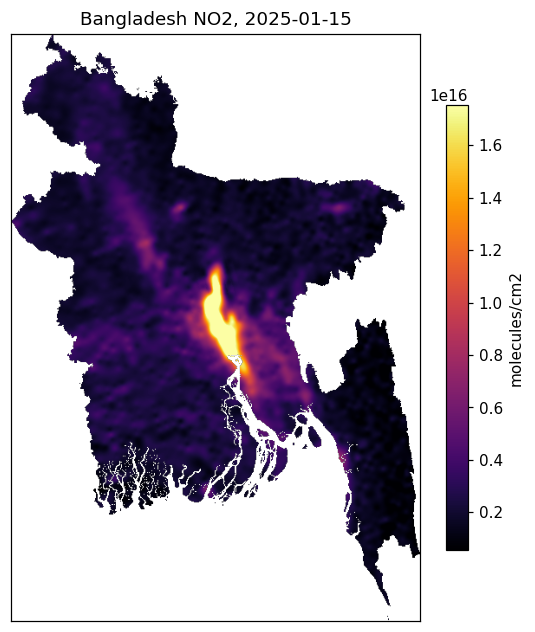

3260 clipped control points -> mean 2.780e+15 molecules/cm2 over the country


In [8]:
# Run the full NO2 pipeline for Bangladesh and map the 1 km surface.

# Filled in by run_bd as each product is processed, so the six-panel figure can reuse them.
bd_grids = {}   # gas -> (gx, gy, grid)
bd_points = {}  # gas -> (lon, lat, val), the clipped control points behind each grid

def run_bd(gas):  # process one Bangladesh product and keep the results
    """Clip and resample one Bangladesh product, store the points and the grid, and return both."""
    lon, lat, val, gx, gy, grid = process_gas(gas, SEGMENTS_BD[gas], AOI["bangladesh"])  # points and grid
    bd_points[gas] = (lon, lat, val)  # store the points
    bd_grids[gas] = (gx, gy, grid)  # store the grid
    return lon, lat, val, gx, gy, grid  # return everything

lon, lat, val, gx, gy, no2_bd = run_bd("no2")  # nitrogen dioxide
fig, ax = plt.subplots(figsize=(6, 7))  # one panel
plot_grid(ax, gx, gy, no2_bd, PRODUCTS["no2"], f"Bangladesh NO2, {DATE_BD}")  # the NO2 map
plt.show()  # draw
# The count is swath pixels inside the border. The mean is taken over the 1 km grid, NaNs ignored.
print(f"{lon.size} clipped control points -> mean {np.nanmean(no2_bd):.3e} molecules/cm2 over the country")

### Sulphur dioxide

SO2 mostly traces heavy industry, power generation from fuel oil or coal, and the traditional
fixed-chimney brick kilns common across central Bangladesh, which burn low grade coal and
biomass. Anthropogenic SO2 columns are small and noisy; never clip negative values before
averaging, since they are retrieval noise distributed around zero, not real negative mass.


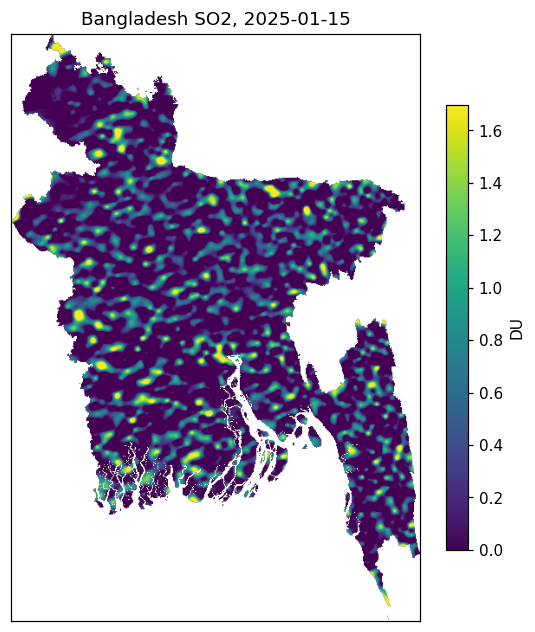

3206 clipped control points -> mean 0.0002 DU over the country


In [9]:
# Run the SO2 pipeline for Bangladesh and map the total column in Dobson units.
# Negative retrieval noise is kept in the grid; floor_zero only holds the colour scale at zero.

lon, lat, val, gx, gy, so2_bd = run_bd("so2")
fig, ax = plt.subplots(figsize=(6, 7))  # one panel
plot_grid(ax, gx, gy, so2_bd, PRODUCTS["so2"], f"Bangladesh SO2, {DATE_BD}")  # the SO2 map
plt.show()  # draw
# number of points and mean SO2
print(f"{lon.size} clipped control points -> mean {np.nanmean(so2_bd):.4f} DU over the country")

### Carbon monoxide

CO comes from incomplete combustion: vehicles, brick kilns, cooking fires and crop residue
burning. It lives long enough, weeks, to carry a regional background signal on top of local
emissions, and its SWIR retrieval is markedly less cloud-sensitive than NO2 or SO2's UV-visible
bands.


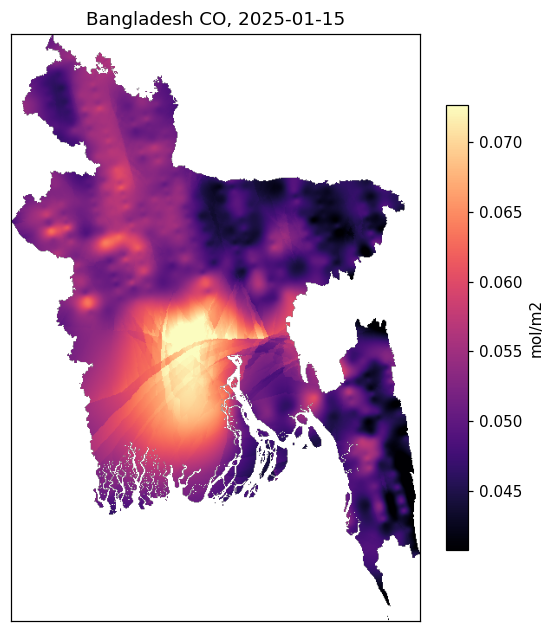

748 clipped control points -> mean 0.0532 mol/m2, about 149 ppb assuming sea level pressure


In [10]:
# Run the CO pipeline for Bangladesh, map the column, and convert the country mean to ppb.

lon, lat, val, gx, gy, co_bd = run_bd("co")
fig, ax = plt.subplots(figsize=(6, 7))  # one panel
plot_grid(ax, gx, gy, co_bd, PRODUCTS["co"], f"Bangladesh CO, {DATE_BD}")  # the CO map
plt.show()  # draw
# co_mixing_ratio turns mol/m2 into a mixing ratio. 101325 Pa is standard sea-level pressure.
xco = s5p.co_mixing_ratio(np.nanmean(co_bd), 101325.0)
# number of points and mean CO
print(f"{lon.size} clipped control points -> mean {np.nanmean(co_bd):.4f} mol/m2, "
     f"about {float(xco):.0f} ppb assuming sea level pressure")

### Methane

Methane is the most demanding of these six products to retrieve: its SWIR band needs a
genuinely clear, low-aerosol, high-reflectance scene. Bangladesh's dry season haze works
against it even on an otherwise clear day, so expect noticeably fewer `qa_value`-passing
pixels than the other five products -- a real limitation of the instrument and the atmosphere,
not a processing bug.


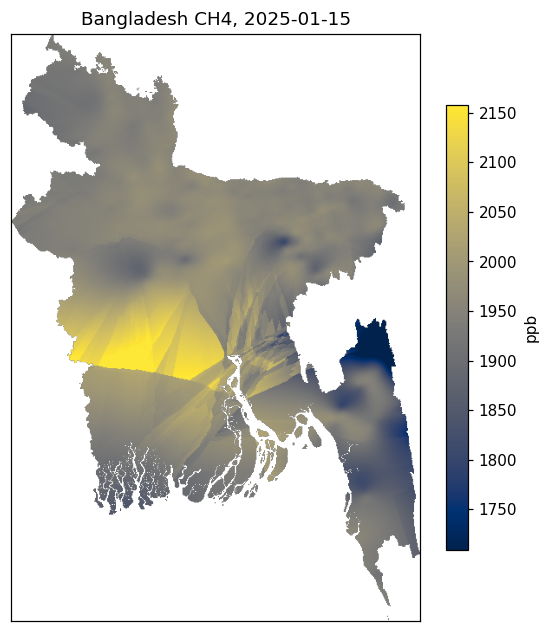

443 clipped control points -> mean 1956.4 ppb over the country
Enhancement above a clean background (~1900 ppb) is consistent with the delta's dense rice paddies, cattle and wetlands rather than with any single city.


In [11]:
# Run the methane pipeline for Bangladesh and map the bias-corrected mixing ratio.
# Fewer control points than the other gases is expected: the SWIR retrieval rejects hazy pixels.

lon, lat, val, gx, gy, ch4_bd = run_bd("ch4")
fig, ax = plt.subplots(figsize=(6, 7))  # one panel
plot_grid(ax, gx, gy, ch4_bd, PRODUCTS["ch4"], f"Bangladesh CH4, {DATE_BD}")  # the methane map
plt.show()  # draw
# number of points and mean CH4
print(f"{lon.size} clipped control points -> mean {np.nanmean(ch4_bd):.1f} ppb over the country")
print("Enhancement above a clean background (~1900 ppb) is consistent with the delta's dense "  # interpretation
     "rice paddies, cattle and wetlands rather than with any single city.")

### Formaldehyde

HCHO is a proxy for volatile organic compound emissions: biomass burning, vehicle exhaust,
industrial solvents and biogenic emissions from vegetation all contribute, so unlike NO2 it
does not read as purely anthropogenic.


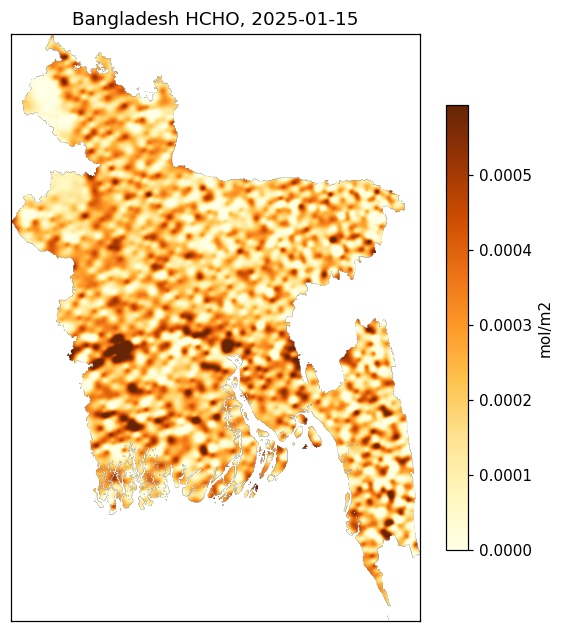

3217 clipped control points -> mean 2.168e-04 mol/m2 over the country


In [12]:
# Run the formaldehyde pipeline for Bangladesh and map the tropospheric column.

lon, lat, val, gx, gy, hcho_bd = run_bd("hcho")
fig, ax = plt.subplots(figsize=(6, 7))  # one panel
plot_grid(ax, gx, gy, hcho_bd, PRODUCTS["hcho"], f"Bangladesh HCHO, {DATE_BD}")  # the formaldehyde map
plt.show()  # draw
# number of points and mean HCHO
print(f"{lon.size} clipped control points -> mean {np.nanmean(hcho_bd):.3e} mol/m2 over the country")

### UV absorbing aerosol index

The aerosol index is not a concentration -- it compares the observed UV reflectance against
what a clean Rayleigh atmosphere would produce. A positive value flags UV-absorbing aerosol
such as smoke, dust and haze; a negative value usually indicates clean air or cloud.


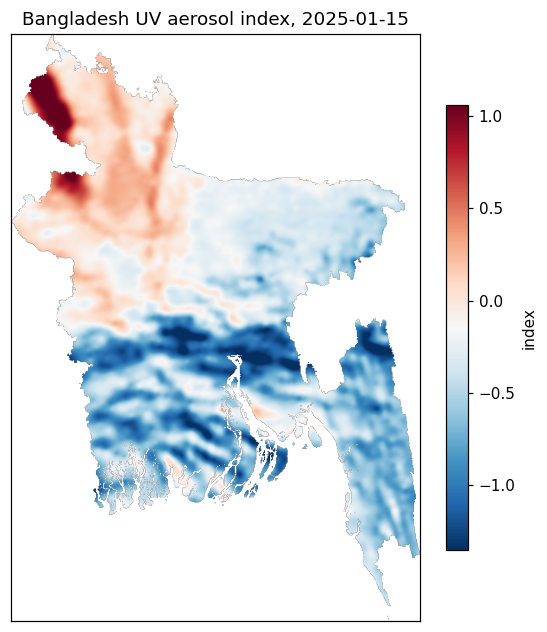

3260 clipped control points -> mean -0.361 over the country


In [13]:
# Run the UV aerosol-index pipeline for Bangladesh and map it.
# Positive values flag absorbing aerosol (smoke, dust, haze); negative values are cleaner air or cloud.

lon, lat, val, gx, gy, ai_bd = run_bd("aer_ai")
fig, ax = plt.subplots(figsize=(6, 7))  # one panel
# the aerosol index map
plot_grid(ax, gx, gy, ai_bd, PRODUCTS["aer_ai"], f"Bangladesh UV aerosol index, {DATE_BD}")
plt.show()  # draw
# number of points and mean index
print(f"{lon.size} clipped control points -> mean {np.nanmean(ai_bd):.3f} over the country")

### A six-pollutant snapshot of Bangladesh

Putting all six products side by side, each already clipped and resampled to the same 1 km
grid, gives one picture of what dry season Bangladesh carries in a single overpass.


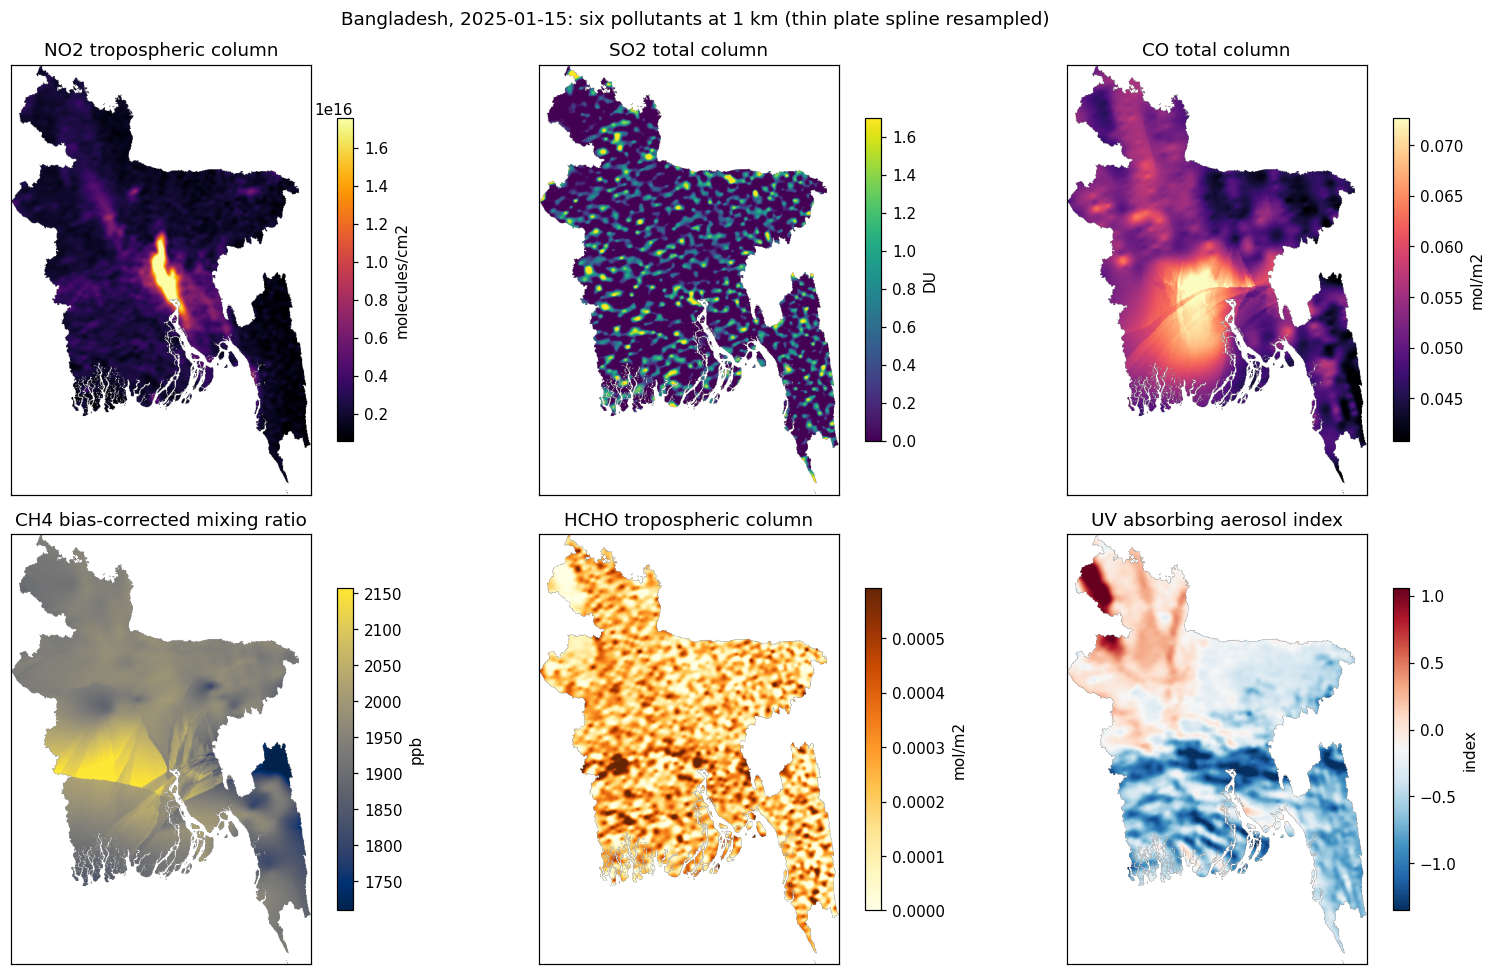

In [14]:
# Draw all six Bangladesh products on one figure, reusing the 1 km grids stored in bd_grids.

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, gas in zip(axes.ravel(), PRODUCTS):  # every product
    gx, gy, grid = bd_grids[gas]  # its grid
    plot_grid(ax, gx, gy, grid, PRODUCTS[gas], PRODUCTS[gas]["label"])  # draw it
plt.suptitle(f"Bangladesh, {DATE_BD}: six pollutants at 1 km (thin plate spline resampled)")  # overall title
plt.tight_layout()  # arrange
plt.show()  # draw

## Case study B: New York State under Canadian wildfire smoke, 15 July 2026

In mid-July 2026, smoke from wildfires burning in Canada drifted south over the northeastern
United States, including New York State. The same six-product pipeline built in the *Boundaries, regional segments and the clip-then-resample workflow* and *Case study A: Bangladesh, dry season, 15 January 2025* sections applies unchanged -- download, clip to the exact state boundary, resample to 1 km -- the only
difference is what the pollutants show: a transient smoke plume rather than Bangladesh's
steady anthropogenic emissions. New York State's larger north-south extent also means every
product here needs two adjacent regional segments, not one, to cover the whole state in a
single overpass, exactly the case `download_segments` and `read_clip_points` were built to
handle.


In [15]:
# Download every New York product for 15 July 2026, or reuse files already on disk.
# This state usually needs two adjacent regional segments per gas to cover its full north-south extent.

DATE_NY = "2026-07-15"
NY_OUT = DATA / "s5p_ny_2026_07_15"  # folder for the New York downloads

# NetCDF files of every gas already on the local drive
local = {gas: sorted((NY_OUT / gas).glob("*.nc")) for gas in PRODUCTS}

if all(local.values()):  # every gas downloaded before
    SEGMENTS_NY = local  # use the local drive
    print("Reading the files already downloaded under", NY_OUT)  # say so
elif ONLINE:  # something is missing: download (download_segments skips files already saved)
    SEGMENTS_NY = {gas: download_segments(gas, NY_BBOX, DATE_NY, NY_OUT) for gas in PRODUCTS}
else:  # offline: use whatever is on disk
    SEGMENTS_NY = local
    print("Offline: reusing the files already downloaded under", NY_OUT)  # say so

for gas, paths in SEGMENTS_NY.items():  # every product
    print(f"{gas:7s} {len(paths)} file(s): " + ", ".join(p.name for p in paths))  # number of files and names

no2     2 file(s): S5P_L2_NO2____20260715T181011_20260715T181511_45362.nc, S5P_L2_NO2____20260715T180511_20260715T181011_45362.nc
so2     2 file(s): S5P_L2_SO2____20260715T181011_20260715T181511_45362.nc, S5P_L2_SO2____20260715T180511_20260715T181011_45362.nc
co      2 file(s): S5P_L2_CO_____20260715T181011_20260715T181511_45362.nc, S5P_L2_CO_____20260715T180511_20260715T181011_45362.nc
ch4     2 file(s): S5P_L2_CH4____20260715T181011_20260715T181511_45362.nc, S5P_L2_CH4____20260715T180511_20260715T181011_45362.nc
hcho    2 file(s): S5P_L2_HCHO___20260715T181011_20260715T181511_45362.nc, S5P_L2_HCHO___20260715T180511_20260715T181011_45362.nc
aer_ai  2 file(s): S5P_L2_AER_AI_20260715T181011_20260715T181511_45362.nc, S5P_L2_AER_AI_20260715T180511_20260715T181011_45362.nc


### Nitrogen dioxide

NO2 is short lived and mostly local (traffic, power generation), so it is not expected to
track a smoke plume the way the next five sections' aerosol- and combustion-linked products
do -- a useful contrast against the *UV absorbing aerosol index* section's aerosol index.


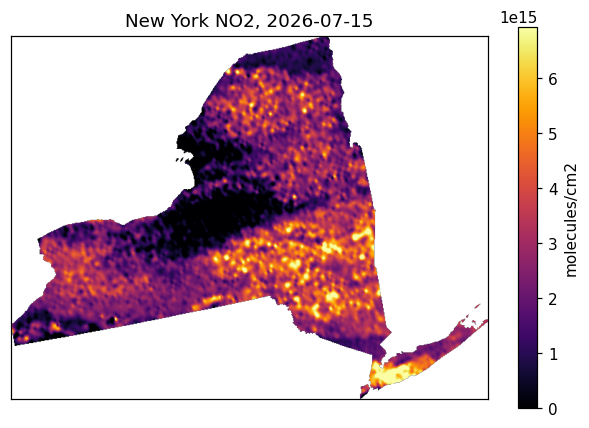

7502 clipped control points -> mean 2.450e+15 molecules/cm2 over the state


In [16]:
# Run the full NO2 pipeline for New York and map the 1 km surface.
# NO2 is short lived, so this map should reflect local emissions more than the smoke plume.

ny_grids = {}   # gas -> (gx, gy, grid); grid is None when too few points survive
ny_points = {}  # gas -> (lon, lat, val), kept so a failed resample can still report a count

def run_ny(gas, min_qa=None):  # process one New York product and keep the results
    """Clip and resample one New York product. min_qa overrides the file's recommended cutoff."""
    # points and grid (optionally with a stricter quality cutoff)
    lon, lat, val, gx, gy, grid = process_gas(gas, SEGMENTS_NY[gas], AOI["ny"], min_qa=min_qa)
    ny_points[gas] = (lon, lat, val)  # store the points
    ny_grids[gas] = (gx, gy, grid)  # store the grid
    return lon, lat, val, gx, gy, grid  # return everything

lon, lat, val, gx, gy, no2_ny = run_ny("no2")  # nitrogen dioxide
fig, ax = plt.subplots(figsize=(7, 6))  # one panel
plot_grid(ax, gx, gy, no2_ny, PRODUCTS["no2"], f"New York NO2, {DATE_NY}")  # the NO2 map
plt.show()  # draw
# number of points and mean NO2
print(f"{lon.size} clipped control points -> mean {np.nanmean(no2_ny):.3e} molecules/cm2 over the state")

### Sulphur dioxide

Wildfire smoke is not a major SO2 source (biomass burning releases far more CO, HCHO and
aerosol than sulphur), so this product mainly tests whether the pipeline still behaves
normally on a smoke day -- a near-zero, noisy signal here is the expected result, not a
failure.


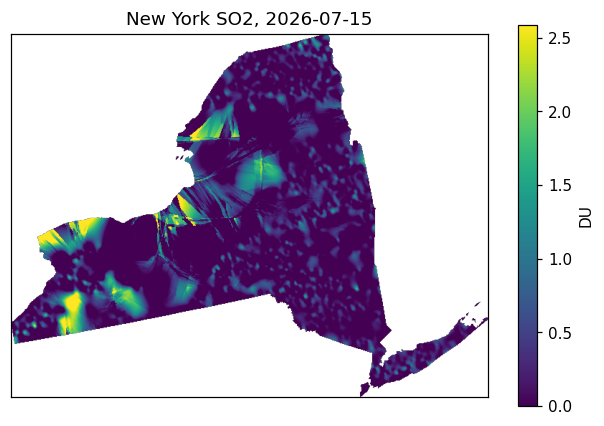

2348 clipped control points -> mean -0.0308 DU over the state


In [17]:
# Run the SO2 pipeline for New York. A near-zero, noisy column is the expected smoke-day result.

lon, lat, val, gx, gy, so2_ny = run_ny("so2")
fig, ax = plt.subplots(figsize=(7, 6))  # one panel
plot_grid(ax, gx, gy, so2_ny, PRODUCTS["so2"], f"New York SO2, {DATE_NY}")  # the SO2 map
plt.show()  # draw
# number of points and mean SO2
print(f"{lon.size} clipped control points -> mean {np.nanmean(so2_ny):.4f} DU over the state")

### Carbon monoxide

CO is one of the two most reliable smoke tracers in this product set: biomass burning is a
major incomplete-combustion source, and CO's multi-week lifetime lets it accumulate across an
entire smoke plume rather than marking only its freshest edge.


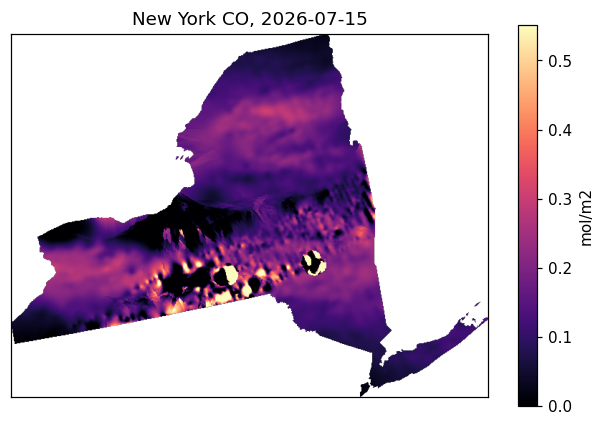

2265 clipped control points -> mean 0.1314 mol/m2, about 368 ppb assuming sea level pressure


In [18]:
# Run the CO pipeline for New York, map the column, and convert the state mean to ppb.
# Biomass burning is a large CO source, so this map should rise with the smoke plume.

lon, lat, val, gx, gy, co_ny = run_ny("co")
fig, ax = plt.subplots(figsize=(7, 6))  # one panel
plot_grid(ax, gx, gy, co_ny, PRODUCTS["co"], f"New York CO, {DATE_NY}")  # the CO map
plt.show()  # draw
xco = s5p.co_mixing_ratio(np.nanmean(co_ny), 101325.0)  # column -> dry-air mixing ratio at sea-level pressure
# number of points, mean column and mixing ratio
print(f"{lon.size} clipped control points -> mean {np.nanmean(co_ny):.4f} mol/m2, "
     f"about {float(xco):.0f} ppb assuming sea level pressure")

### Methane: a second data availability case study

The *Methane* section showed methane struggling under Bangladesh's ordinary dry season haze. Thick
wildfire smoke is a far more extreme version of the same obstacle: TROPOMI's SWIR CH4
retrieval needs a clear, high-reflectance scene, and a heavy smoke plume is neither. Check the
raw `qa_value` coverage before even trying to resample, rather than silently handing a 5-point
"map" to a thin plate spline and letting it extrapolate a smooth-looking fiction across the
whole state.


In [19]:
# Count methane pixels over New York that pass qa_value before trying to resample.
# A thin plate spline on a handful of points would draw a smooth map that the data do not support.

for p in SEGMENTS_NY["ch4"]:
    ds = s5p.read_ch4(p)  # read the methane file
    # Pixel centres inside the state polygon, not merely inside the search bounding box.
    inside = shapely.contains_xy(AOI["ny"]["geo"], ds.longitude.values.ravel(), ds.latitude.values.ravel())
    qa_in_state = ds["qa_value"].values.ravel()[inside]  # quality values of pixels over the state
    print(f"{p.name}: {inside.sum()} pixels over New York, "  # pixels and quality per file
         f"mean qa_value {qa_in_state.mean():.3f}, {(qa_in_state >= 0.5).sum()} pass qa >= 0.5")

# process_gas returns grid=None (and gx is None) when fewer than MIN_TPS_POINTS survive.
lon, lat, val, gx, gy, ch4_ny = run_ny("ch4")
# too few points to grid
print(f"\n{lon.size} control points survive clipping -- below MIN_TPS_POINTS={MIN_TPS_POINTS}, "
     "so no 1 km surface is fitted" if gx is None else f"{lon.size} control points, mean {np.nanmean(ch4_ny):.1f} ppb")

S5P_L2_CH4____20260715T181011_20260715T181511_45362.nc: 2560 pixels over New York, mean qa_value 0.005, 2 pass qa >= 0.5
S5P_L2_CH4____20260715T180511_20260715T181011_45362.nc: 1300 pixels over New York, mean qa_value 0.009, 3 pass qa >= 0.5



5 control points survive clipping -- below MIN_TPS_POINTS=20, so no 1 km surface is fitted


A handful of pixels pass quality filtering out of several thousand in the search area --
the same mechanism as the *Methane* section, far more pronounced. Smoke scatters and absorbs enough SWIR
radiance that the retrieval algorithm itself flags most of the scene as unreliable; the gap in
The *A six-pollutant snapshot of New York under smoke* section's combined figure is this finding stated plainly, not a plotting error.


### Formaldehyde

HCHO is the second strong smoke tracer here: biomass burning releases volatile organic
compounds directly, and sunlight breaks many of them down into HCHO within hours, so a fresh
plume shows up clearly.


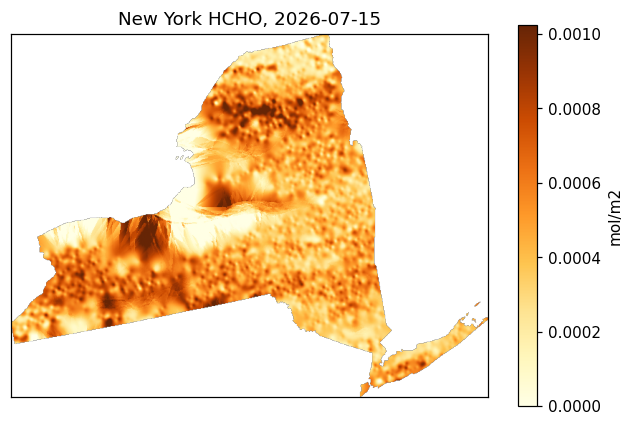

3816 clipped control points -> mean 4.522e-04 mol/m2 over the state


In [20]:
# Run the formaldehyde pipeline for New York. Fresh smoke should raise the tropospheric column.

lon, lat, val, gx, gy, hcho_ny = run_ny("hcho")
fig, ax = plt.subplots(figsize=(7, 6))  # one panel
plot_grid(ax, gx, gy, hcho_ny, PRODUCTS["hcho"], f"New York HCHO, {DATE_NY}")  # the formaldehyde map
plt.show()  # draw
# number of points and mean HCHO
print(f"{lon.size} clipped control points -> mean {np.nanmean(hcho_ny):.3e} mol/m2 over the state")

### UV absorbing aerosol index

This is the cleanest single signal of smoke in the whole product set. Wildfire smoke is a
textbook UV-absorbing aerosol, and Bangladesh's dry season values in the *UV absorbing aerosol index* section (roughly -1
to +1) give a useful sense of scale for how extreme a true smoke event reads by comparison.


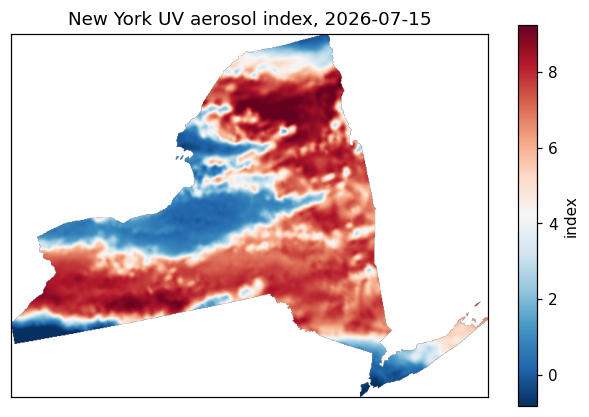

7613 clipped control points -> mean 5.353, max 9.805 over the state


In [21]:
# Run the UV aerosol-index pipeline for New York and report the mean and the maximum.
# Wildfire smoke is strongly UV-absorbing, so the maximum is the clearest plume signal.

lon, lat, val, gx, gy, ai_ny = run_ny("aer_ai")
fig, ax = plt.subplots(figsize=(7, 6))  # one panel
# the aerosol index map
plot_grid(ax, gx, gy, ai_ny, PRODUCTS["aer_ai"], f"New York UV aerosol index, {DATE_NY}")
plt.show()  # draw
print(f"{lon.size} clipped control points -> mean {np.nanmean(ai_ny):.3f}, "  # number of points and mean index
     f"max {np.nanmax(ai_ny):.3f} over the state")

### A six-pollutant snapshot of New York under smoke

The same combined layout as the *A six-pollutant snapshot of Bangladesh* section, with one difference: the *Methane: a second data availability case study* section found too few
quality-passing methane pixels under this much smoke to fit a 1 km surface at all, so that
panel reports the finding in text instead of drawing a fabricated map.


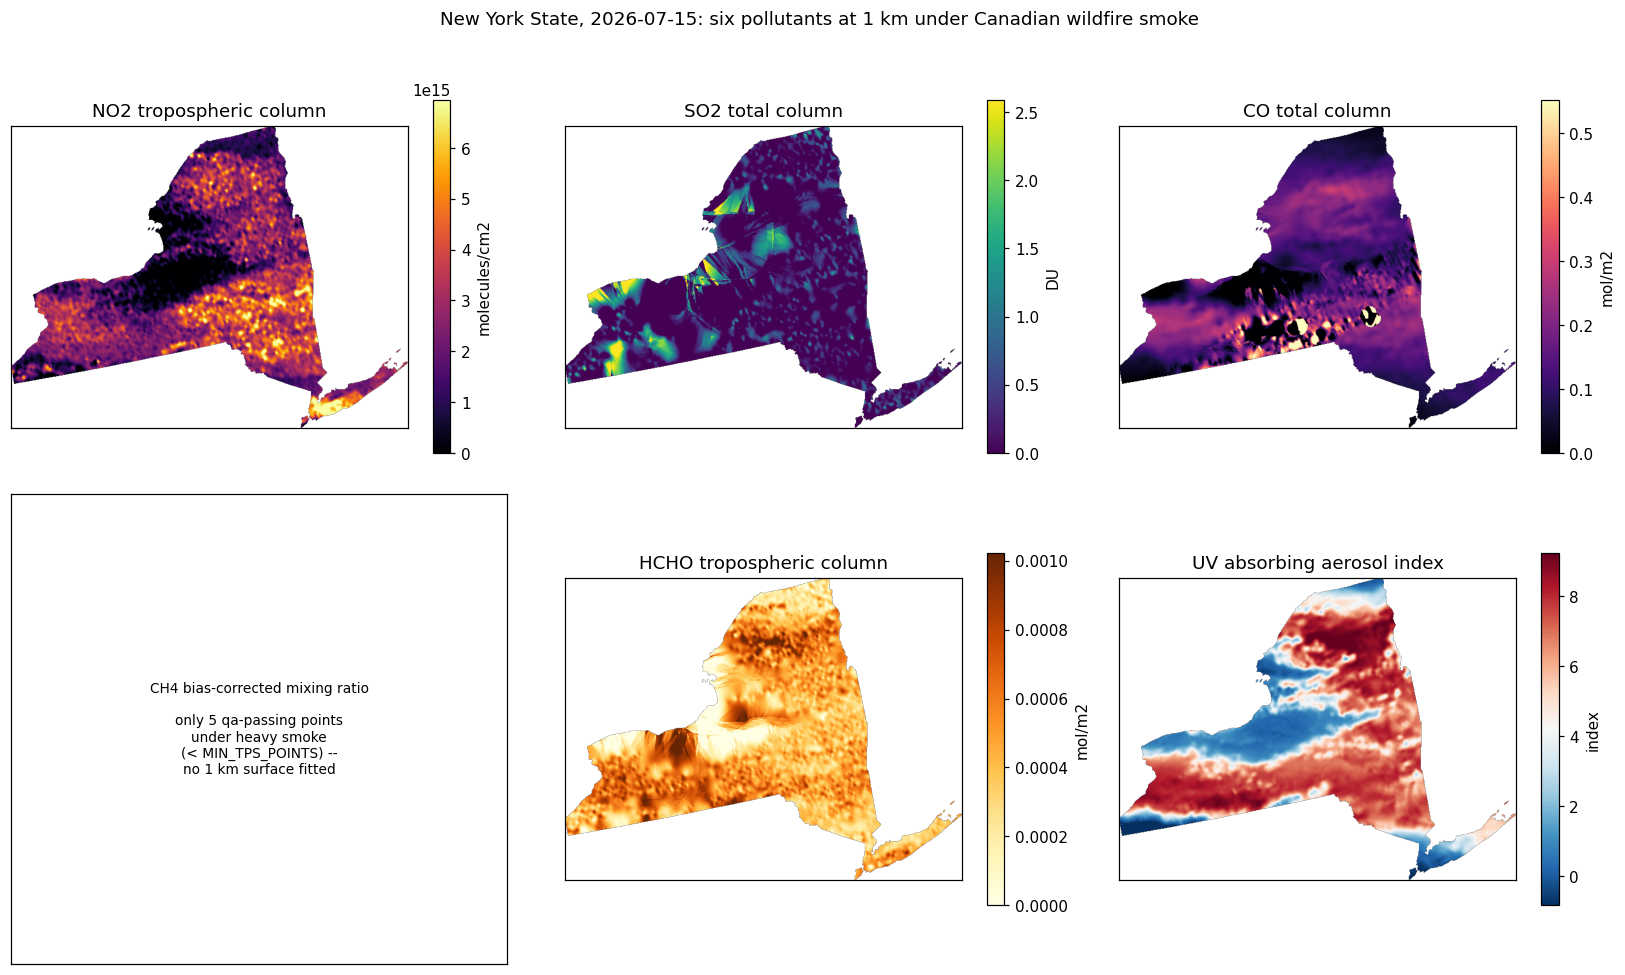

In [22]:
# Six-panel New York figure. A product with too few points gets a text note instead of a map.

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, gas in zip(axes.ravel(), PRODUCTS):  # every product
    gx, gy, grid = ny_grids[gas]  # its grid
    if grid is None:  # not enough points to grid
        # ny_points[gas][0] is the longitude array, so its length is the surviving point count.
        n = ny_points[gas][0].size
        # explain in the panel
        ax.text(0.5, 0.5, f"{PRODUCTS[gas]['label']}\n\nonly {n} qa-passing points\nunder heavy smoke\n"
               "(< MIN_TPS_POINTS) --\nno 1 km surface fitted",
               ha="center", va="center", fontsize=9, transform=ax.transAxes)
        ax.set_xticks([]); ax.set_yticks([])  # no ticks
        for spine in ax.spines.values():  # keep the panel frame
            spine.set_visible(True)  # visible
    else:
        plot_grid(ax, gx, gy, grid, PRODUCTS[gas], PRODUCTS[gas]["label"])  # draw the grid
# overall title
plt.suptitle(f"New York State, {DATE_NY}: six pollutants at 1 km under Canadian wildfire smoke")
plt.tight_layout()  # arrange
plt.show()  # draw

## Checking processing consistency across combined downloads

`check_processing_consistency` reads only global attributes, so it is cheap to run before
trusting a result built from more than one file. Bangladesh needed only one file per product,
trivially self-consistent; New York's two adjacent regional segments per product are exactly
the case worth checking -- `read_clip_points` already concatenated them into one set of control
points on the assumption that they share a processing baseline. Confirm that assumption here,
after the fact, rather than take it on faith.


In [23]:
# Confirm that the New York segments combined for each gas share one processing baseline.
# check_processing_consistency reads global attributes only, so it stays cheap even for a full orbit.

for gas, paths in SEGMENTS_NY.items():
    consistency = s5p.check_processing_consistency(paths)  # processor versions of the files
    # An empty flag means the files agree. Any other flag is a processor or pixel-size mismatch.
    bad = consistency[consistency["flag"] != ""]
    status = "OK" if bad.empty else f"{len(bad)} file(s) flagged"  # OK, or the number of flagged files
    # summary per product
    print(f"{gas:7s} {len(paths)} segment(s), processor {consistency['processor_version'].unique().tolist()}: {status}")
# Show the last gas (methane) in full: filename, processor version, pixel-size era, and flag.
consistency[["path", "processor_version", "pixel_size_era", "flag"]].assign(
    path=lambda d: d["path"].map(lambda p: Path(p).name))

no2     2 segment(s), processor ['02.09.01']: OK
so2     2 segment(s), processor ['02.08.00']: OK
co      2 segment(s), processor ['02.09.01']: OK


ch4     2 segment(s), processor ['02.09.01']: OK
hcho    2 segment(s), processor ['02.08.00']: OK
aer_ai  2 segment(s), processor ['02.09.01']: OK


,path,processor_version,pixel_size_era,flag
0,S5P_L2_AER_AI_20260715T181011_20260715T181511_...,02.09.01,5.5km (post-2019-08-06),
1,S5P_L2_AER_AI_20260715T180511_20260715T181011_...,02.09.01,5.5km (post-2019-08-06),


## Summary, exercises and references

**Key ideas**

- Sentinel-5P's TROPOMI measures NO2, SO2, CO, CH4, HCHO, ozone, aerosol and cloud from a
  single instrument, daily, at 5.5 by 3.5 km, with a swath wide enough to cover a whole country
  or state in one or two regional segments rather than a tile mosaic.
- Always filter by qa_value. The right threshold differs by product and is written into the
  variable's own metadata, not fixed across the mission.
- Clip to the exact administrative boundary polygon, not just its bounding box, and average any
  duplicate geolocations where adjacent regional segments overlap, before fitting anything.
- A thin plate spline, fitted in a projected (metres) CRS and evaluated on a regular 1 km grid,
  turns a sparse, irregular swath into a usable dense raster where simple cell averaging would
  leave most cells empty -- at the cost of some overshoot near sparse edges, handled here with
  robust percentile colour limits rather than the raw data range.
- Bangladesh's six products, mapped on an ordinary dry season day, each tell a related but
  distinct story: NO2 and SO2 mark combustion point sources, CO carries a longer-lived regional
  background, CH4 reflects the delta's agriculture more than any city, and aerosol index gives
  a clean single number for the dry season haze.
- The same pipeline applied to New York under Canadian wildfire smoke shows CO, HCHO and
  especially aerosol index responding strongly to a transient plume that NO2 and SO2, both tied
  to local anthropogenic sources, do not track.
- A genuine data availability limit, methane's retrieval collapsing under heavy smoke, is a
  real scientific finding worth reporting plainly (the *Methane: a second data availability case study* section), not a bug to paper over with a
  misleading extrapolated map.
- Check processing consistency across any files a single analysis combines, including two
  regional segments of the same overpass, not only a multi-date time series.

**`geolattice.rsense.atmosphere.sentinel_5p` functions used:** `read_no2`, `read_so2`, `read_co`,
`read_ch4`, `read_hcho`, `read_aerosol_index`, `qa_mask`, `molecules_per_cm2`, `dobson_units`,
`co_mixing_ratio`, `check_processing_consistency`.

**Exercises**

1. Repeat the *Case study A: Bangladesh, dry season, 15 January 2025* section for a different single day in December 2024 or January 2025 and compare
   the NO2 and aerosol index means against 15 January 2025 -- is this date typical of the dry
   season, or unusually clean or polluted?
2. New York's state boundary clips tightly around a smoke plume that almost certainly extended
   well into neighbouring Vermont, Massachusetts and Pennsylvania. Download the same date for
   one neighbouring state (reusing `AOI`, `download_segments` and `process_gas` unchanged) and
   check whether the aerosol index gradient in the *UV absorbing aerosol index* section continues smoothly across the
   border.
3. `tps_resample` uses `neighbors=25`. Rerun the *Nitrogen dioxide* section with `neighbors=10` and `neighbors=60`
   and compare the resulting NO2 maps -- what changes, and why does a local thin plate spline
   behave differently from a global one as `neighbors` grows?
4. Use `read_so2` with `layer_height="7km"` on the New York SO2 files to check whether any
   residual SO2 signal in the *Sulphur dioxide* section is more consistent with a different plume height
   assumption than the default boundary-layer column.
5. Pick a second wildfire smoke date within a few days of 15 July 2026 (the *Boundaries, regional segments and the clip-then-resample workflow* section's
   `download_segments` function works for any date) and build a small two-date CO and aerosol
   index comparison to see whether the plume was strengthening or weakening over New York.
